# Projeto M2 — Segmentação e Morfologia
**Disciplina:** Processamento de Imagens — Prof. Felipe Viel  
**Curso:** Ciência da Computação — UNIVALI

**Integrantes:**
- Eduardo José de Souza
- Miguel Pezzini Kuhr
- Nicolas Mendonça Melo Fajardo

Implementação dos **Projetos 1 e 2** e da **Opção 2 de Morfologia**, seguindo
`docs/Trabalho M2.pdf`. A organização segue `docs/ref_organizacao.ipynb`.

O objetivo é comparar a segmentação por agrupamento nas imagens de maçãs e a
segmentação por cor e por crescimento de regiões nas imagens de rostos.
As máscaras de pele são refinadas com abertura e fechamento.


## 0. Setup

Execute as células em ordem. As dependências estão em `requirements.txt`.
Utilizamos as mesmas bibliotecas básicas do trabalho anterior: NumPy, Pandas,
Matplotlib e OpenCV. A exibição acontece no notebook, sem abrir janelas externas.

**Uso das bibliotecas:** leitura, redução das imagens e K-means usam OpenCV;
os gráficos usam Matplotlib e as tabelas, Pandas. No Projeto 2, as conversões
de cor, as regras de limiarização e o crescimento de regiões são implementados
com NumPy e uma fila. A morfologia também é implementada manualmente.
`connectedComponents` será usado apenas para contar componentes na análise.


In [1]:
from pathlib import Path
from collections import deque
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

IMG_DIR = Path('imgs')
MAX_LADO = 480  # Redução proporcional para os experimentos não demorarem muito.
SEED = 42
plt.rcParams['figure.dpi'] = 100


def read(nome):
    img = cv2.imread(str(IMG_DIR / nome))
    if img is None:
        raise FileNotFoundError(f'Não foi possível ler {IMG_DIR / nome}')
    return img


def reduzir(img, max_lado=MAX_LADO):
    h, w = img.shape[:2]
    escala = min(1, max_lado / max(h, w))
    if escala == 1:
        return img.copy()
    return cv2.resize(img, (round(w * escala), round(h * escala)),
                      interpolation=cv2.INTER_AREA)


def show_images(imagens, titulos):
    fig, axes = plt.subplots(1, len(imagens), figsize=(4 * len(imagens), 4))
    for ax, img, titulo in zip(np.atleast_1d(axes), imagens, titulos):
        if img.ndim == 2:
            ax.imshow(img, cmap='gray', vmin=0, vmax=1 if img.dtype == bool else 255)
        else:
            ax.imshow(img[..., ::-1])  # OpenCV lê BGR; Matplotlib mostra RGB.
        ax.set_title(titulo)
        ax.axis('off')
    plt.tight_layout()
    plt.show()


def aplicar_mascara(img, mascara):
    resultado = img.copy()
    resultado[~mascara] = 0
    return resultado


## 1. Projeto 1 — K-means em RGB e RGB+XY

**Enunciado resumido:** segmentar as imagens de maçãs com K-means usando (A) as
três componentes RGB e (B) RGB e as coordenadas X e Y. Comparar os resultados e
mostrar a dispersão 3D RGB de `2or4objects.jpg`.

O K-means alterna dois passos: atribui cada pixel ao centro mais próximo e
atualiza cada centro pela média dos pixels atribuídos a ele. Aqui usamos
`cv2.kmeans`, permitido no Projeto 1, com a mesma ideia do código de referência.

### 1.1. Imagens e escolha de K

Incluímos um grupo adicional para o fundo: K=3 nas duas maçãs, K=8 nas sete
maçãs e K=4 nos três objetos coloridos. Em `2or4objects.jpg`, K=5 permite
explorar as duas maçãs e os dois corações, além do fundo; também testamos K=3.
Esses valores são pontos de partida baseados nos objetos visíveis.
**K é o número de grupos de pixels, não uma garantia de contar objetos:**
maçãs com a mesma cor podem compartilhar um grupo, e sombras podem criar outro.


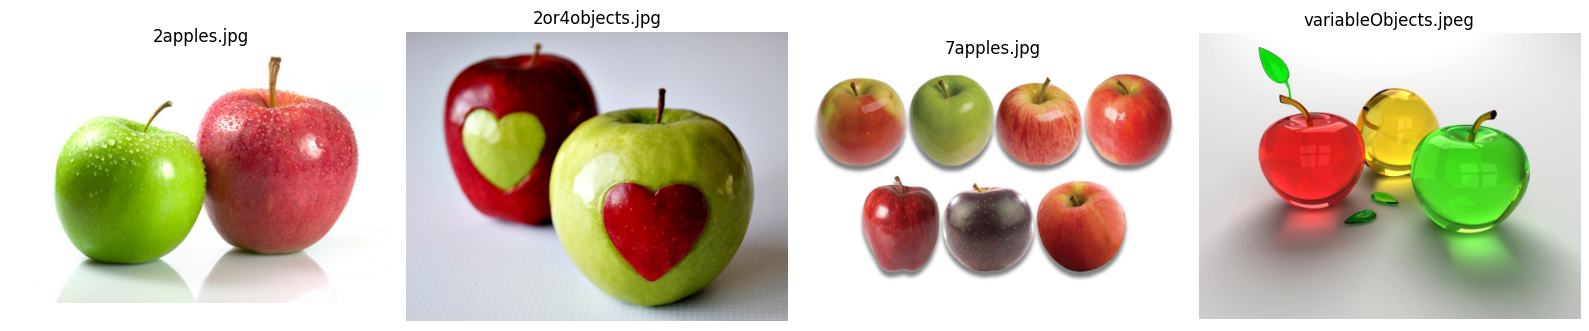

In [2]:
CONFIG_MACAS = {
    '2apples.jpg': 3,
    '2or4objects.jpg': 5,
    '7apples.jpg': 8,
    'variableObjects.jpeg': 4,
}
macas = {nome: reduzir(read(nome)) for nome in CONFIG_MACAS}
show_images(list(macas.values()), list(macas))


### 1.2. Função de agrupamento

RGB é dividido por 255 e X e Y são divididos pela largura e altura, ficando
entre 0 e 1. Sem isso, a dimensão com os maiores valores dominaria a distância.
O parâmetro `peso_xy=0.5` controla a influência da posição: valores maiores
favorecem grupos espacialmente próximos, mas podem dividir uma mesma maçã.
No modo RGB, pixels distantes com cores parecidas podem ficar no mesmo grupo.


In [3]:
def KMeans(img, k, usar_xy=False, peso_xy=0.5):
    h, w = img.shape[:2]
    rgb = img[..., ::-1].astype(np.float32) / 255.0
    dados = rgb.reshape(-1, 3)

    if usar_xy:
        y, x = np.indices((h, w), dtype=np.float32)
        xy = np.column_stack((x.ravel() / max(w - 1, 1),
                              y.ravel() / max(h - 1, 1)))
        dados = np.column_stack((dados, peso_xy * xy))

    dados = np.ascontiguousarray(dados, dtype=np.float32)
    criterio = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 60, 0.001)
    cv2.setRNGSeed(SEED)
    _, rotulos, centros = cv2.kmeans(dados, k, None, criterio, 5,
                                    cv2.KMEANS_PP_CENTERS)
    rotulos = rotulos.reshape(h, w)
    # Os primeiros três atributos dos centros são RGB nos dois modos.
    rgb_segmentado = np.clip(centros[rotulos, :3] * 255, 0, 255).astype(np.uint8)
    return {'imagem': rgb_segmentado[..., ::-1], 'rotulos': rotulos,
            'centros': centros}


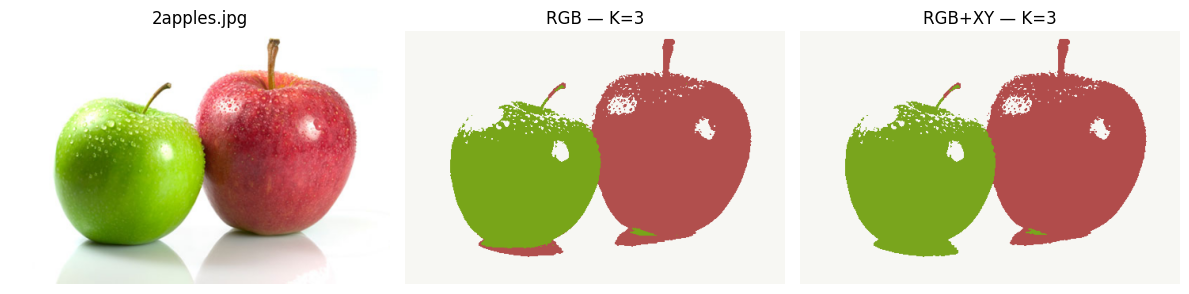

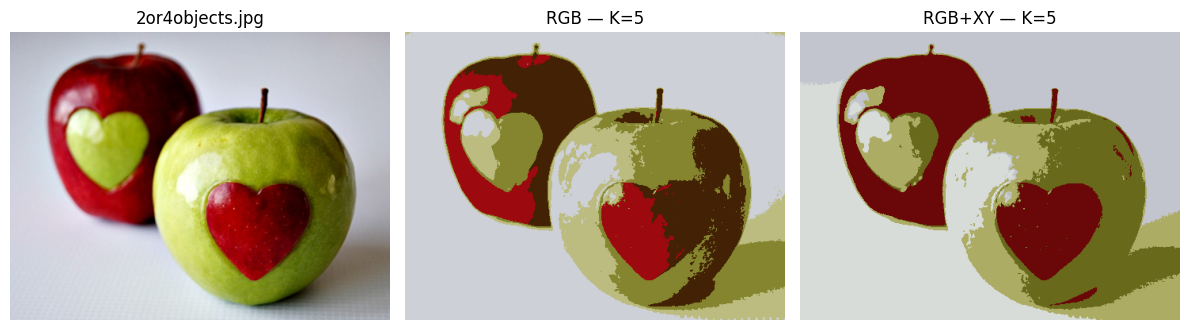

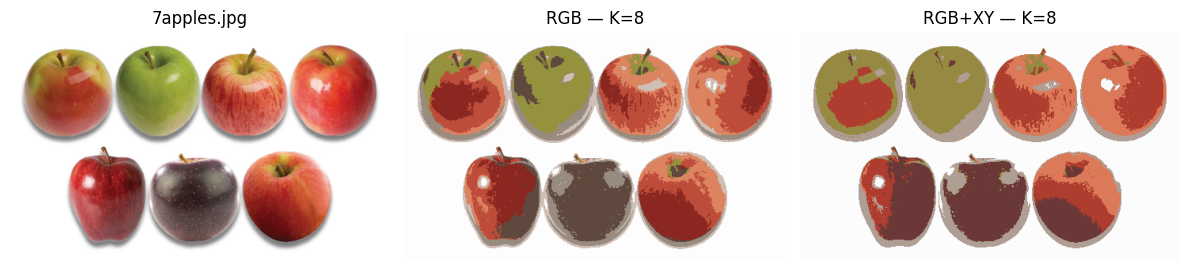

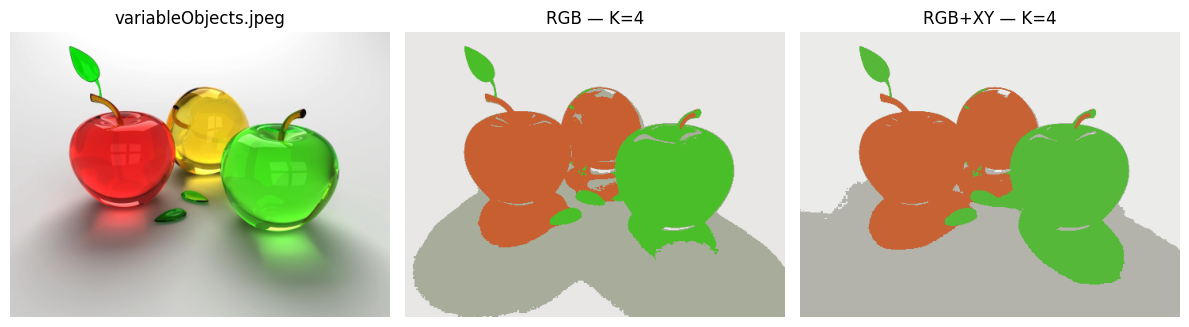

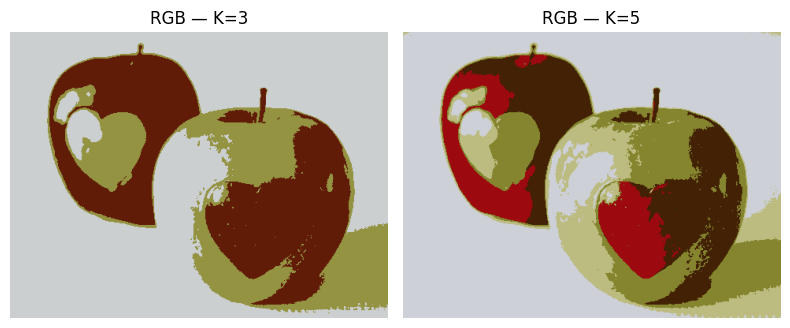

In [4]:
resultados_kmeans = {}
for nome, img in macas.items():
    k = CONFIG_MACAS[nome]
    rgb = KMeans(img, k)
    rgb_xy = KMeans(img, k, usar_xy=True)
    resultados_kmeans[nome] = {'RGB': rgb, 'RGB+XY': rgb_xy}
    show_images([img, rgb['imagem'], rgb_xy['imagem']],
                [nome, f'RGB — K={k}', f'RGB+XY — K={k}'])

# Comparação adicional: duas maçãs ou quatro regiões coloridas?
img = macas['2or4objects.jpg']
show_images([KMeans(img, 3)['imagem'], KMeans(img, 5)['imagem']],
            ['RGB — K=3', 'RGB — K=5'])


### 1.3. Dispersão 3D — 2or4objects.jpg

Os eixos correspondem aos valores RGB dos pixels da imagem de entrada.
A cor de cada ponto representa seu grupo no K-means RGB, e os X indicam os
centros. Mostramos uma amostra reprodutível de até 4.000 pixels apenas para
deixar o gráfico legível; o agrupamento utiliza todos os pixels da imagem reduzida.


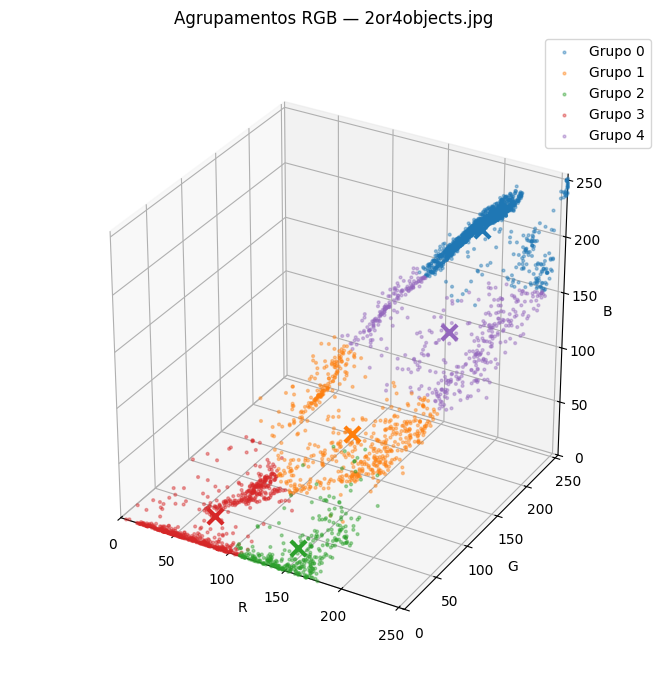

In [5]:
img = macas['2or4objects.jpg']
res = resultados_kmeans['2or4objects.jpg']['RGB']
pixels = img[..., ::-1].reshape(-1, 3)
rotulos = res['rotulos'].ravel()
centros = res['centros'][:, :3] * 255
rng = np.random.default_rng(SEED)
amostra = rng.choice(len(pixels), min(4000, len(pixels)), replace=False)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')
cores = plt.get_cmap('tab10')
for grupo in range(CONFIG_MACAS['2or4objects.jpg']):
    pontos = pixels[amostra[rotulos[amostra] == grupo]]
    ax.scatter(pontos[:, 0], pontos[:, 1], pontos[:, 2], s=4, alpha=0.4,
               color=cores(grupo), label=f'Grupo {grupo}')
    ax.scatter(*centros[grupo], marker='x', s=120, linewidths=3,
               color=cores(grupo))
ax.set(xlabel='R', ylabel='G', zlabel='B',
       xlim=(0, 255), ylim=(0, 255), zlim=(0, 255),
       title='Agrupamentos RGB — 2or4objects.jpg')
ax.legend()
ax.set_box_aspect((1, 1, 1), zoom=0.85)
plt.tight_layout()
plt.show()


### 1.4. Comparação RGB × RGB+XY

A comparação visual deve considerar se cores iguais em locais diferentes
foram agrupadas e se uma maçã acabou dividida em regiões. RGB prioriza a
semelhança de cor; RGB+XY também penaliza a distância espacial. Adicionar XY
pode ajudar a separar regiões afastadas, mas não impõe conectividade nem
entende o significado de uma maçã.

A tabela abaixo mede apenas a alteração média das cores após o agrupamento
(RMSE em RGB). Um valor menor indica melhor reprodução das cores originais,
**não necessariamente melhor separação dos objetos**. Não comparamos as somas
das distâncias internas do K-means, pois os espaços têm dimensões diferentes.

**Observações da execução:** em `2apples.jpg`, os dois modos separam as cores
principais de forma parecida. Em `2or4objects.jpg`, RGB+XY deixa algumas
regiões mais uniformes, mas ainda há sombras e reflexos misturados aos grupos.
Em `7apples.jpg`, cada maçã continua podendo ter mais de um grupo. Em
`variableObjects.jpeg`, K=4 junta partes dos objetos vermelho e amarelo;
o fundo e as sombras também consomem grupos. Isso mostra que escolher K pelo
número de objetos é uma aproximação, e não uma contagem confiável de maçãs.


In [6]:
linhas = []
for nome, modos in resultados_kmeans.items():
    for modo, res in modos.items():
        erro = macas[nome].astype(float) - res['imagem'].astype(float)
        linhas.append({'Imagem': nome, 'Modo': modo, 'K': CONFIG_MACAS[nome],
                       'RMSE de cor': np.sqrt(np.mean(erro ** 2))})
display(pd.DataFrame(linhas).round(2))


,Imagem,Modo,K,RMSE de cor
0,2apples.jpg,RGB,3,28.10
1,2apples.jpg,RGB+XY,3,28.13
2,2or4objects.jpg,RGB,5,23.12
3,2or4objects.jpg,RGB+XY,5,25.57
4,7apples.jpg,RGB,8,14.60
5,7apples.jpg,RGB+XY,8,18.52
6,variableObjects.jpeg,RGB,4,27.78
7,variableObjects.jpeg,RGB+XY,4,28.07


## 2. Projeto 2 — Segmentação de pele e crescimento de regiões

**Enunciado resumido:** implementar do zero uma limiarização de cor para pele
e um crescimento de regiões iniciado em um pixel selecionado manualmente na
face. Comparar RGB e HSV e discutir métricas de segmentação.

Esses métodos selecionam pixels compatíveis com pele. Isso serve como etapa
inicial para localizar rostos, mas não diferencia semanticamente rosto, pescoço,
braço ou fundo com cor semelhante.

### 2.1. Conversões de cor

O artigo de Kolkur et al. apresenta H em graus e S entre 0 e 1. Por isso,
calculamos HSV diretamente com NumPy. Não normalizamos HSV pelo mínimo e
máximo da imagem, pois isso mudaria os limites de uma foto para outra.

Para YCrCb, usamos a convenção digital em 0–255, com crominâncias centradas
em 128, compatível com o esqueleto que utiliza OpenCV. A seção 3.2 do artigo
contém fórmulas simplificadas/inconsistentes com essa escala; registramos aqui
a convenção adotada para aplicar os limites da seção 4. A ordem é **Y, Cr, Cb**.


In [7]:
def bgr_para_hsv(img):
    rgb = img[..., ::-1].astype(float) / 255
    r, g, b = rgb[..., 0], rgb[..., 1], rgb[..., 2]
    maior = rgb.max(axis=-1)
    menor = rgb.min(axis=-1)
    delta = maior - menor
    h = np.zeros_like(maior)
    s = np.zeros_like(maior)

    tem_cor = delta > 0
    mr = tem_cor & (maior == r)
    mg = tem_cor & (maior == g) & ~mr
    mb = tem_cor & ~mr & ~mg
    h[mr] = ((g[mr] - b[mr]) / delta[mr]) % 6
    h[mg] = (b[mg] - r[mg]) / delta[mg] + 2
    h[mb] = (r[mb] - g[mb]) / delta[mb] + 4
    np.divide(delta, maior, out=s, where=maior > 0)
    return np.stack((h * 60, s, maior), axis=-1)


def bgr_para_ycrcb(img):
    b, g, r = [img[..., i].astype(float) for i in range(3)]
    y = 0.299 * r + 0.587 * g + 0.114 * b
    cr = (r - y) * 0.713 + 128
    cb = (b - y) * 0.564 + 128
    return np.stack((y, cr, cb), axis=-1)


### 2.2. Limiarização de cor — regras do artigo

Na seção 4 (página 328), o artigo usa:

- RGB: R > 95, G > 40, B > 20, R > G, R > B e |R − G| > 15.
- HSV: 0 ≤ H ≤ 50 graus e 0,23 ≤ S ≤ 0,68.
- YCrCb: Y > 80, Cr > 135, Cb > 85 e cinco restrições lineares entre Cr e Cb.

Também calculamos a combinação do artigo:
**(RGB e HSV) ou (RGB e YCrCb)**. Ela não equivale à união simples das três
máscaras. O canal alfa é dispensado porque as fotos JPEG são opacas (A=255).
Os nomes das funções mantêm a ligação com `docs/SkinSegmentation.py`.
Não utilizamos funções prontas de segmentação neste projeto.


In [8]:
def RGB_Threshold(bgr):
    b, g, r = [bgr[..., i].astype(float) for i in range(3)]
    return ((r > 95) & (g > 40) & (b > 20) &
            (r > g) & (r > b) & (np.abs(r - g) > 15))


def HSV_Threshold(hsv):
    h, s = hsv[..., 0], hsv[..., 1]
    return (h >= 0) & (h <= 50) & (s >= 0.23) & (s <= 0.68)


def YCrCb_Threshold(ycrcb):
    y, cr, cb = [ycrcb[..., i] for i in range(3)]
    return ((y > 80) & (cr > 135) & (cb > 85) &
            (cr <= 1.5862 * cb + 20) &
            (cr >= 0.3448 * cb + 76.2069) &
            (cr >= -4.5652 * cb + 234.5652) &
            (cr <= -1.15 * cb + 301.75) &
            (cr <= -2.2857 * cb + 432.85))


def SkinSegmentation(img):
    rgb = RGB_Threshold(img)
    hsv = HSV_Threshold(bgr_para_hsv(img))
    ycrcb = YCrCb_Threshold(bgr_para_ycrcb(img))
    combinada = (rgb & hsv) | (rgb & ycrcb)
    return {'RGB': rgb, 'HSV': hsv, 'YCrCb': ycrcb, 'Combinada': combinada}


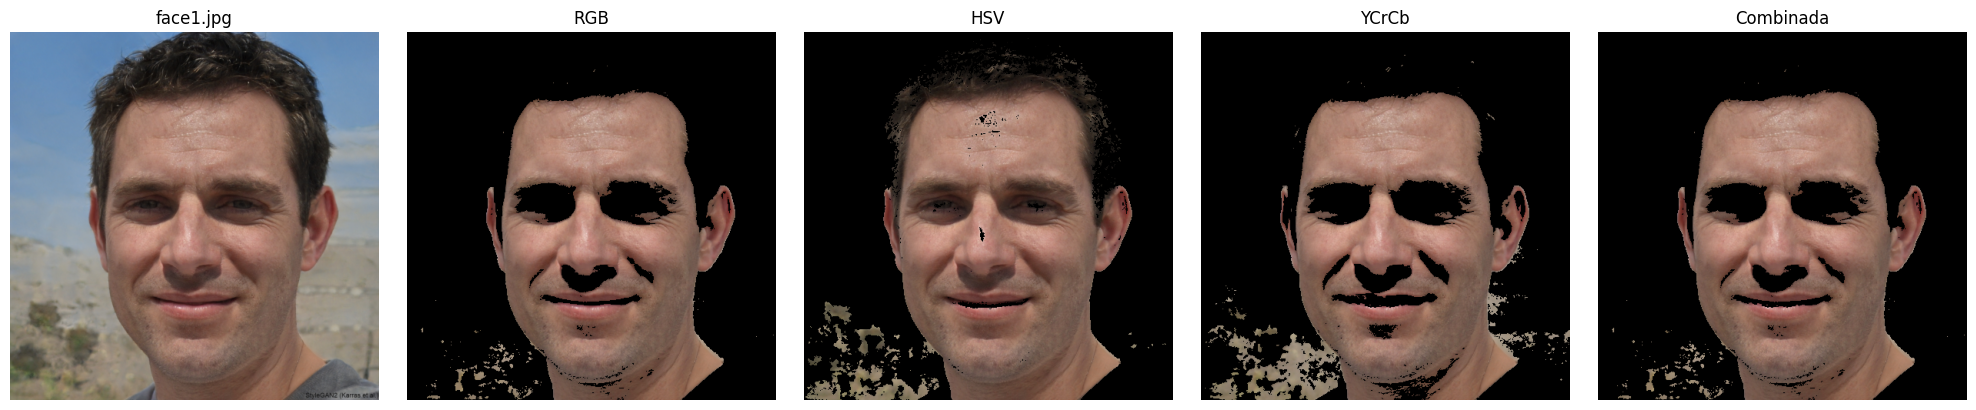

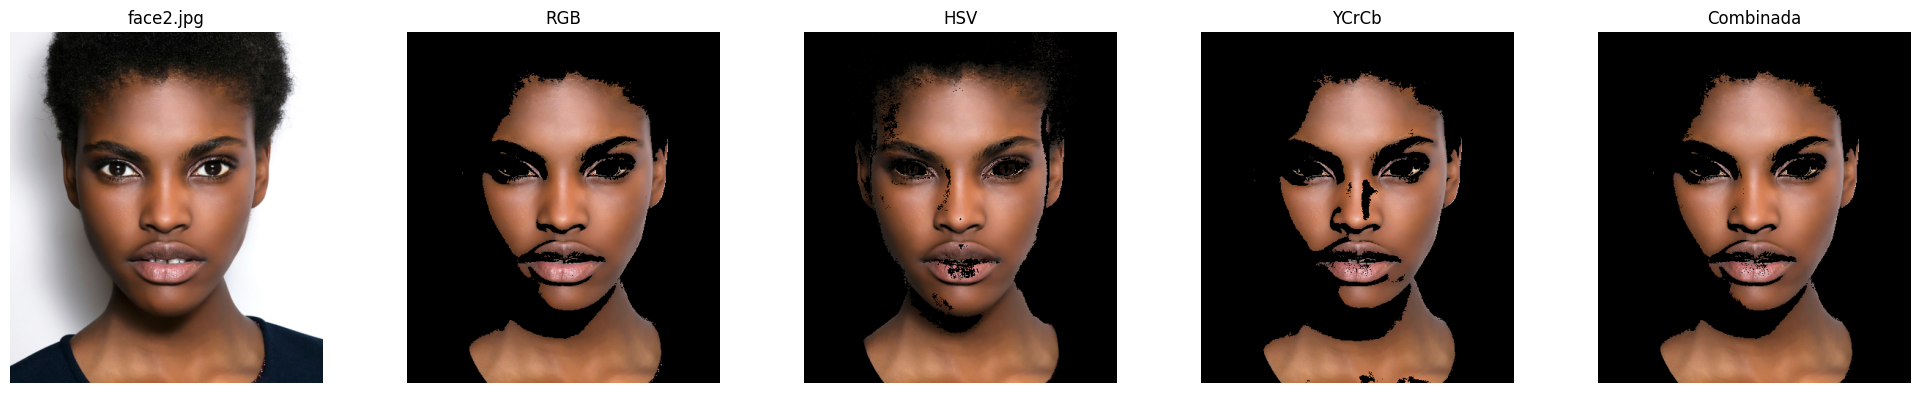

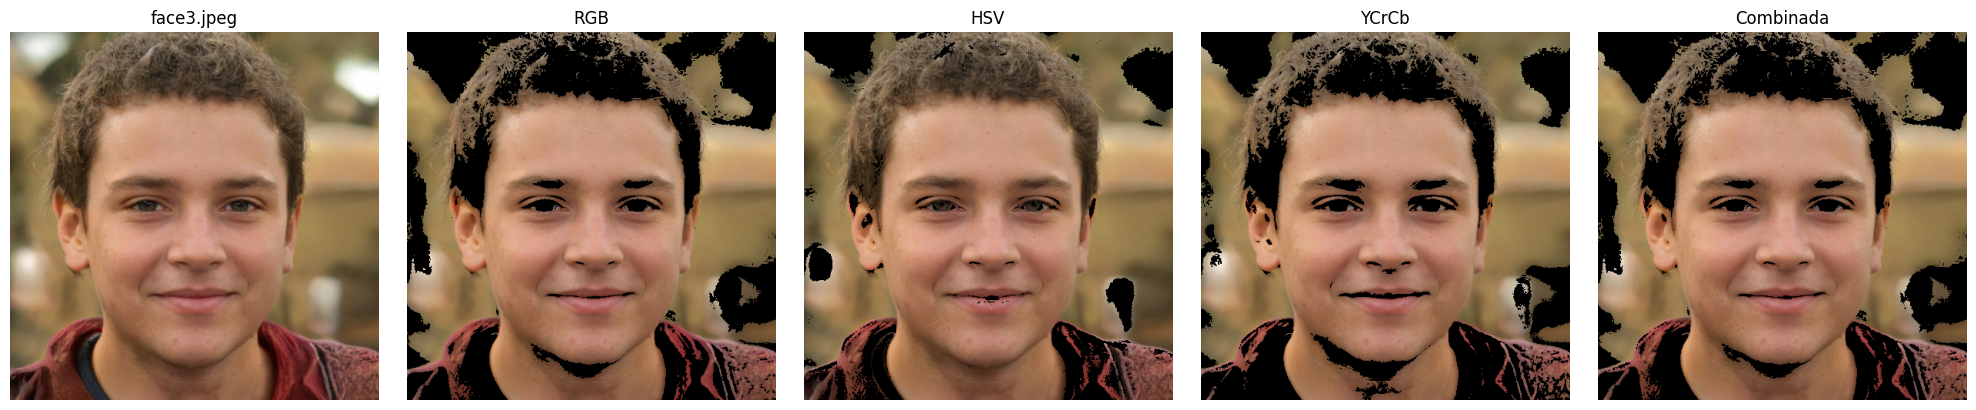

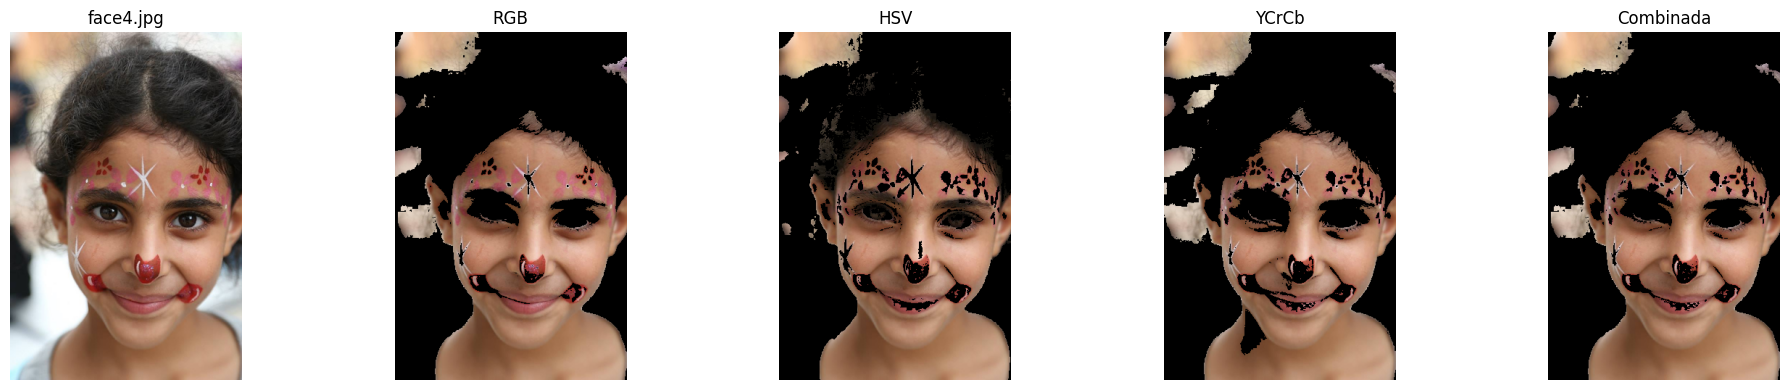

In [9]:
NOMES_FACES = ['face1.jpg', 'face2.jpg', 'face3.jpeg', 'face4.jpg']
originais_faces = {nome: read(nome) for nome in NOMES_FACES}
faces = {nome: reduzir(img) for nome, img in originais_faces.items()}
mascaras_pele = {}

for nome, img in faces.items():
    mascaras_pele[nome] = SkinSegmentation(img)
    show_images([img] + [aplicar_mascara(img, m)
                        for m in mascaras_pele[nome].values()],
                [nome] + list(mascaras_pele[nome]))


### 2.3. RGB é um bom espaço de cores ou HSV é melhor?

RGB permite uma regra simples, mas seus canais mudam juntos com a iluminação.
HSV separa o matiz e a saturação do brilho, facilitando definir uma faixa de
cor de pele. Porém, em regiões pouco saturadas, o matiz fica instável, e os
limites fixos ainda podem excluir partes da pele ou aceitar o fundo.

Assim, HSV é uma escolha mais conveniente para especificar os limites de cor,
mas não é garantidamente melhor em todas as fotos. A comparação exibida acima
permite observar essas falhas e o efeito da combinação com RGB e YCrCb.
Sem máscaras verdadeiras, não é possível afirmar qual tem maior acurácia.

Nas saídas desta execução, HSV preserva mais regiões sombreadas de `face1.jpg`
e `face2.jpg`, mas também seleciona cabelo e outras áreas. Em `face3.jpeg`,
o fundo tem cores próximas da pele e aparece em grande parte das três
limiarizações; a máscara combinada também mantém esse erro. Em `face4.jpg`,
a pintura facial interrompe algumas regiões de pele, e há seleção de fundo.


### 2.4. Crescimento de regiões a partir de uma semente manual

Cada semente é definida em **(linha, coluna)** nas coordenadas da foto original,
em uma região de pele da testa. O código converte a posição para a imagem
reduzida e a marca em vermelho para permitir a conferência.

Mantemos uma fila e a média BGR dos pixels aceitos. Um vizinho entra se a
diferença em **cada canal** for menor que a tolerância. Só vizinhos de pixels
aceitos são explorados, usando conectividade 4 (cima, baixo, esquerda e direita).
A fila evita os limites de profundidade de uma função recursiva.

O parâmetro é uma porcentagem da escala 0–255: 15% corresponde a 38,25 níveis
por canal. Como no esqueleto, cada candidato é examinado uma vez; candidatos
rejeitados não são revisitados depois que a média muda. A ordem da visita pode
influenciar o resultado. A semente é contada apenas uma vez na média.


In [10]:
# Posições escolhidas manualmente ao inspecionar as fotos originais.
SEMENTES_ORIGINAIS = {
    'face1.jpg': (300, 500),
    'face2.jpg': (240, 350),
    'face3.jpeg': (350, 500),
    'face4.jpg': (260, 200),
}
# Em face2, 15% selecionou só uma pequena parte da testa; 25% expande a região.
TOLERANCIAS = {'face1.jpg': 15, 'face2.jpg': 25, 'face3.jpeg': 15, 'face4.jpg': 15}


def converter_semente(semente, original, reduzida):
    h0, w0 = original.shape[:2]
    h, w = reduzida.shape[:2]
    linha, coluna = semente
    return (min(h - 1, round(linha * h / h0)),
            min(w - 1, round(coluna * w / w0)))


def SeedPointSegmentation(img, seedPoint, tolerance=15):
    h, w = img.shape[:2]
    linha, coluna = seedPoint
    if not (0 <= linha < h and 0 <= coluna < w):
        raise ValueError('Semente fora da imagem.')
    if not (0 <= tolerance <= 100):
        raise ValueError('A tolerância deve estar entre 0 e 100%.')

    limite = 255 * tolerance / 100
    dados = img.astype(float)  # Evita subtração com overflow de uint8.
    visitado = np.zeros((h, w), dtype=bool)
    mascara = np.zeros((h, w), dtype=bool)
    visitado[linha, coluna] = mascara[linha, coluna] = True
    soma = dados[linha, coluna].copy()
    quantidade = 1
    fila = deque([(linha, coluna)])

    while fila:
        l, c = fila.popleft()
        for dl, dc in [(1, 0), (-1, 0), (0, -1), (0, 1)]:
            nl, nc = l + dl, c + dc
            if not (0 <= nl < h and 0 <= nc < w) or visitado[nl, nc]:
                continue
            visitado[nl, nc] = True
            media = soma / quantidade
            if np.all(np.abs(dados[nl, nc] - media) < limite):
                mascara[nl, nc] = True
                soma += dados[nl, nc]
                quantidade += 1
                fila.append((nl, nc))
    return mascara


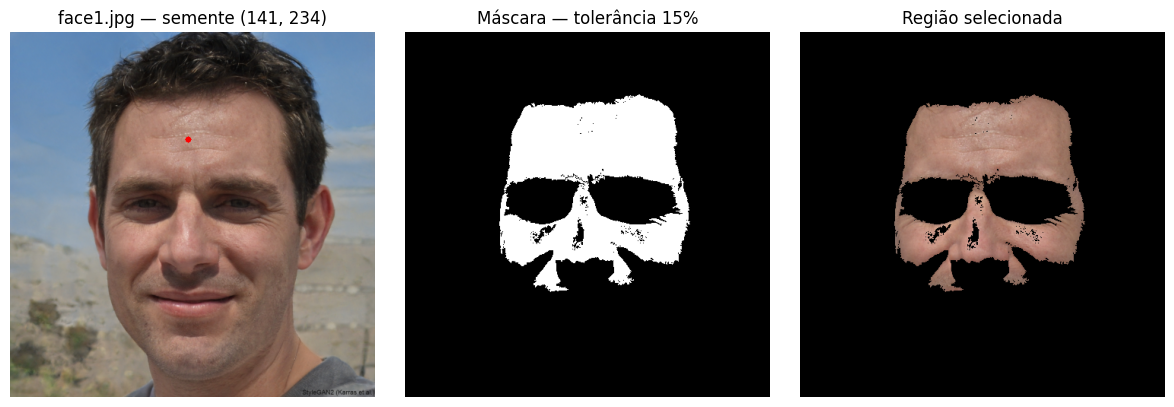

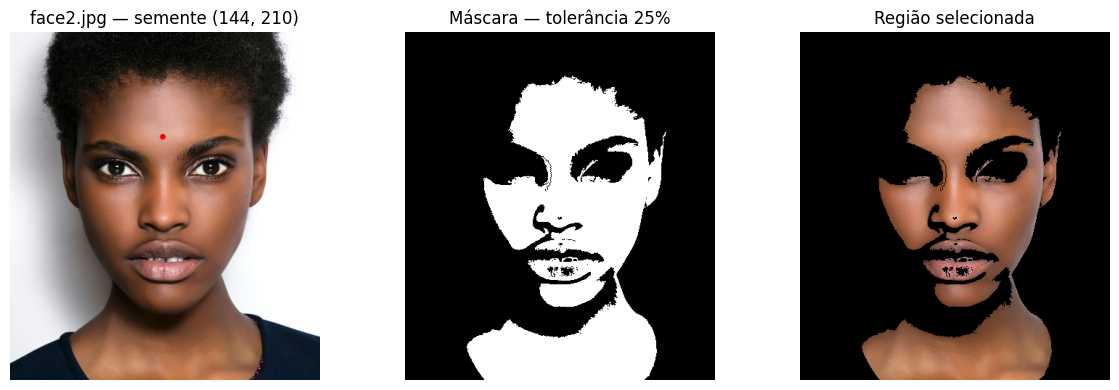

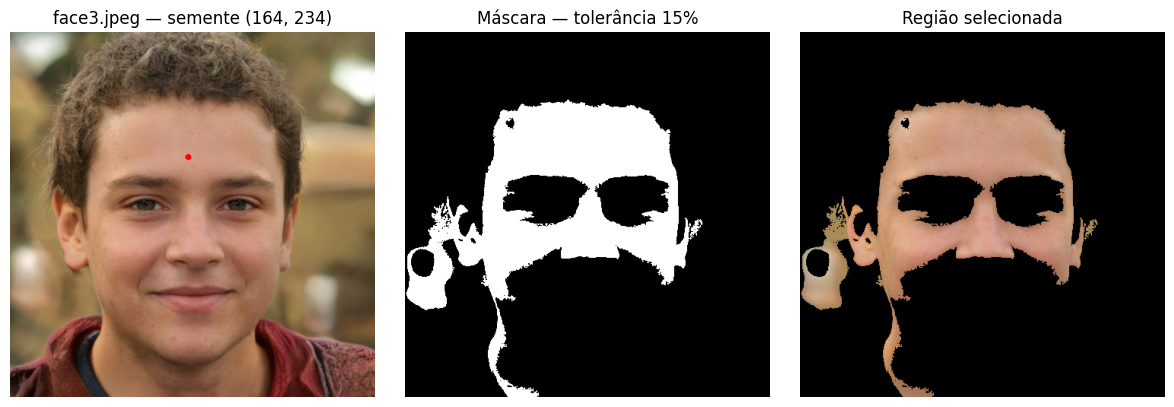

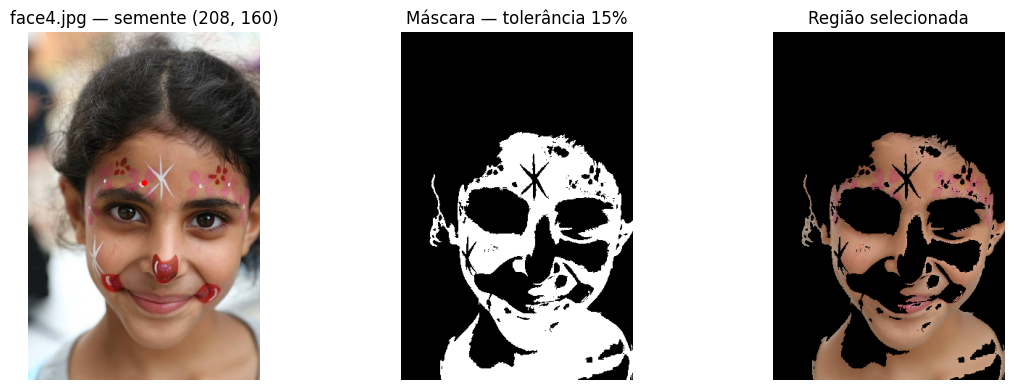

In [11]:
mascaras_semeadas = {}
sementes = {}
for nome, img in faces.items():
    semente = converter_semente(SEMENTES_ORIGINAIS[nome], originais_faces[nome], img)
    sementes[nome] = semente
    mascara = SeedPointSegmentation(img, semente, TOLERANCIAS[nome])
    mascaras_semeadas[nome] = mascara
    marcada = img.copy()
    cv2.circle(marcada, (semente[1], semente[0]), 4, (0, 0, 255), -1)
    show_images([marcada, mascara, aplicar_mascara(img, mascara)],
                [f'{nome} — semente {semente}',
                 f'Máscara — tolerância {TOLERANCIAS[nome]}%', 'Região selecionada'])


### 2.5. Efeito da tolerância

Mantemos a semente fixa e comparamos 8%, 15% e 25% em `face1.jpg`.
Tolerâncias pequenas tendem a interromper o crescimento nas sombras;
tolerâncias maiores permitem mais variação, mas podem incluir cabelo, roupa
ou fundo. A média móvel também pode se deslocar para cores indesejadas.

Em `face2.jpg`, a configuração final usa 25%: com 15%, o crescimento ficou
restrito à testa. Mesmo com o ajuste, sombras e olhos ainda interrompem a
região. Em `face3.jpeg`, já se observa vazamento para partes do fundo com 15%.


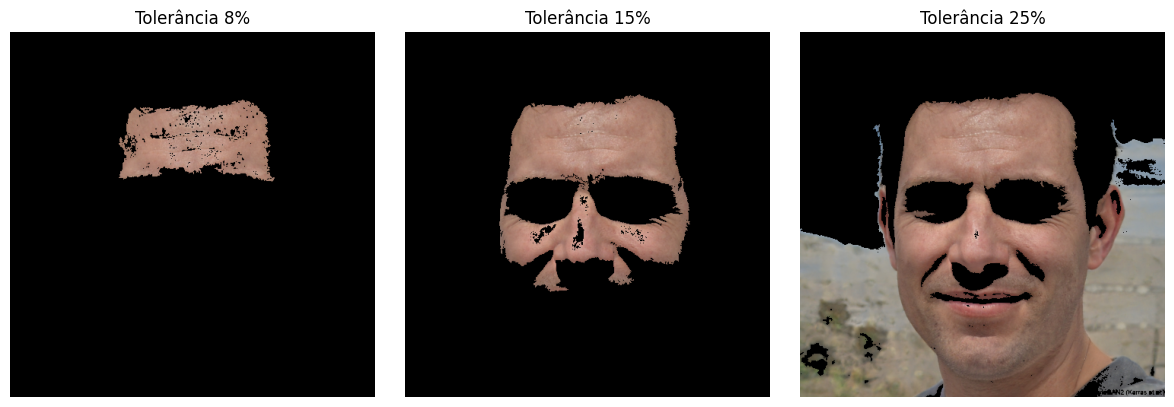

In [12]:
nome = 'face1.jpg'
img = faces[nome]
tolerancias_teste = [8, 15, 25]
teste_tolerancia = [SeedPointSegmentation(img, sementes[nome], t)
                    for t in tolerancias_teste]
show_images([aplicar_mascara(img, m) for m in teste_tolerancia],
            [f'Tolerância {t}%' for t in tolerancias_teste])


## 3. Morfologia — Opção 2 (Projeto 2)

Escolhemos esta opção porque as máscaras binárias do Projeto 2 já estão
disponíveis, dispensando selecionar quais grupos de maçãs pertencem ao objeto.

- **Erosão:** mantém um pixel apenas se todos os vizinhos do elemento
  estruturante pertencerem à máscara; reduz as regiões.
- **Dilatação:** mantém um pixel se algum desses vizinhos pertencer à máscara;
  expande as regiões.
- **Abertura:** erosão seguida de dilatação; remove pequenas regiões e pontas.
- **Fechamento:** dilatação seguida de erosão; reduz pequenos buracos e falhas.

As funções abaixo usam um elemento quadrado de tamanho ímpar e deslocamentos
da máscara com NumPy, sem chamar as operações morfológicas prontas do OpenCV.
Usamos borda neutra: fora da imagem vale verdadeiro na erosão e falso na
dilatação, evitando uma faixa artificial nas regiões que tocam a borda.


In [13]:
def morfologia(mascara, tamanho=3, operacao='erosao'):
    if tamanho < 1 or tamanho % 2 == 0:
        raise ValueError('O tamanho deve ser positivo e ímpar.')
    if operacao not in ('erosao', 'dilatacao'):
        raise ValueError('Operação inválida.')
    mascara = np.asarray(mascara, dtype=bool)
    h, w = mascara.shape
    raio = tamanho // 2
    erodir = operacao == 'erosao'
    borda = np.pad(mascara, raio, mode='constant', constant_values=erodir)
    resultado = np.full((h, w), erodir, dtype=bool)
    for l in range(tamanho):
        for c in range(tamanho):
            vizinhos = borda[l:l + h, c:c + w]
            if erodir:
                resultado &= vizinhos
            else:
                resultado |= vizinhos
    return resultado


def erosao(mascara, tamanho=3):
    return morfologia(mascara, tamanho, 'erosao')


def dilatacao(mascara, tamanho=3):
    return morfologia(mascara, tamanho, 'dilatacao')


def abertura(mascara, tamanho=3):
    return dilatacao(erosao(mascara, tamanho), tamanho)


def fechamento(mascara, tamanho=3):
    return erosao(dilatacao(mascara, tamanho), tamanho)


### 3.1. Máscara original → abertura → fechamento

Aplicamos a mesma sequência às máscaras RGB, HSV, combinada e semeada de
cada foto. O elemento 3×3 é pequeno para preservar detalhes da face.
As dimensões se referem aos pixels das imagens reduzidas.


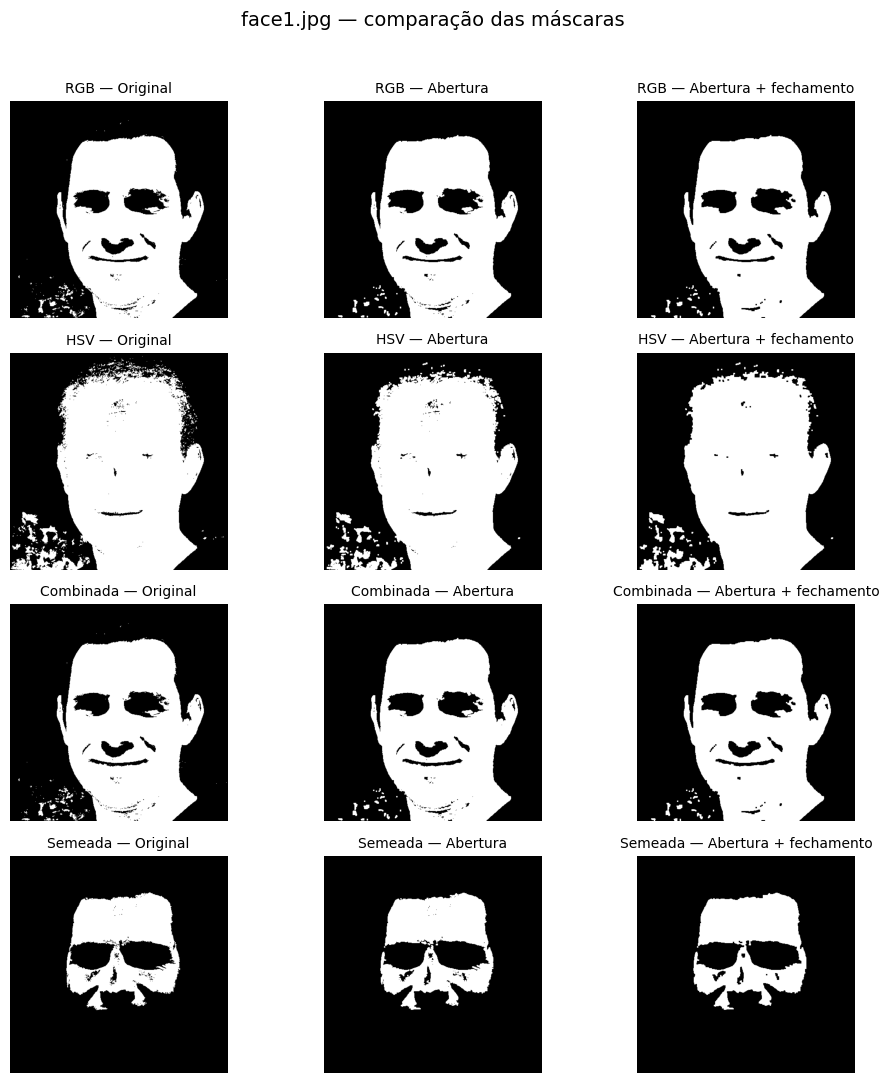

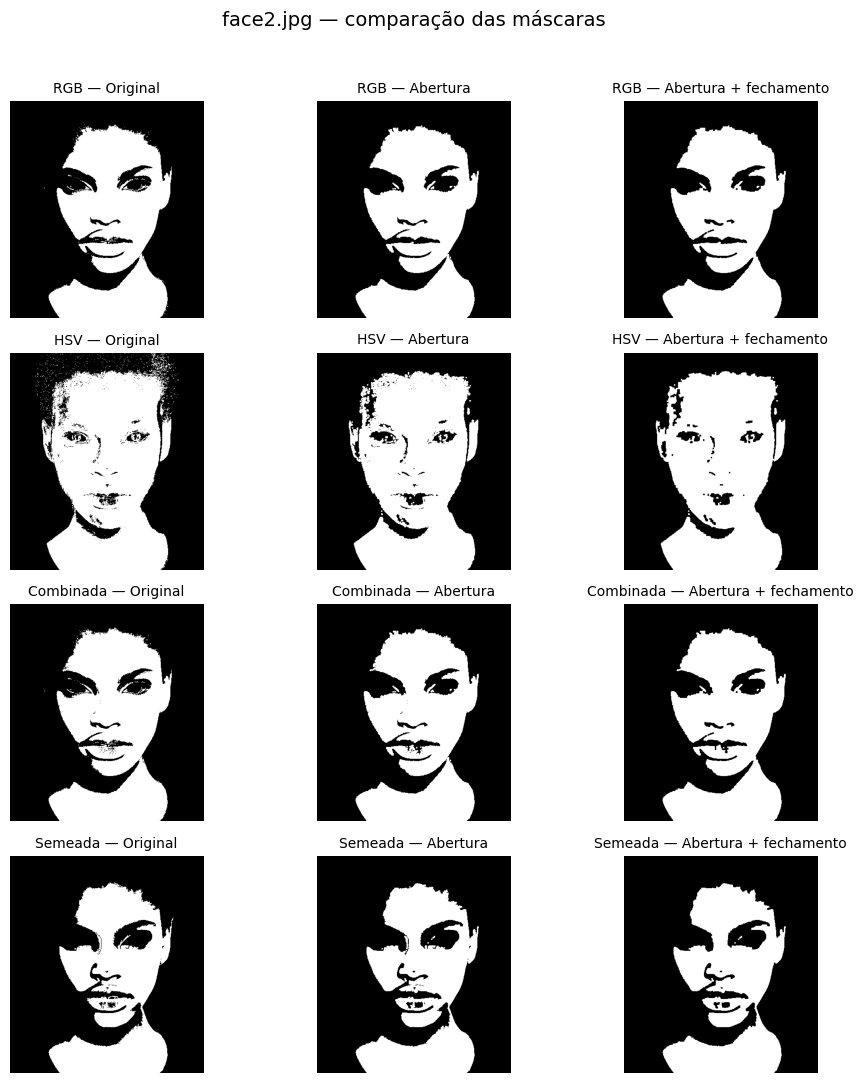

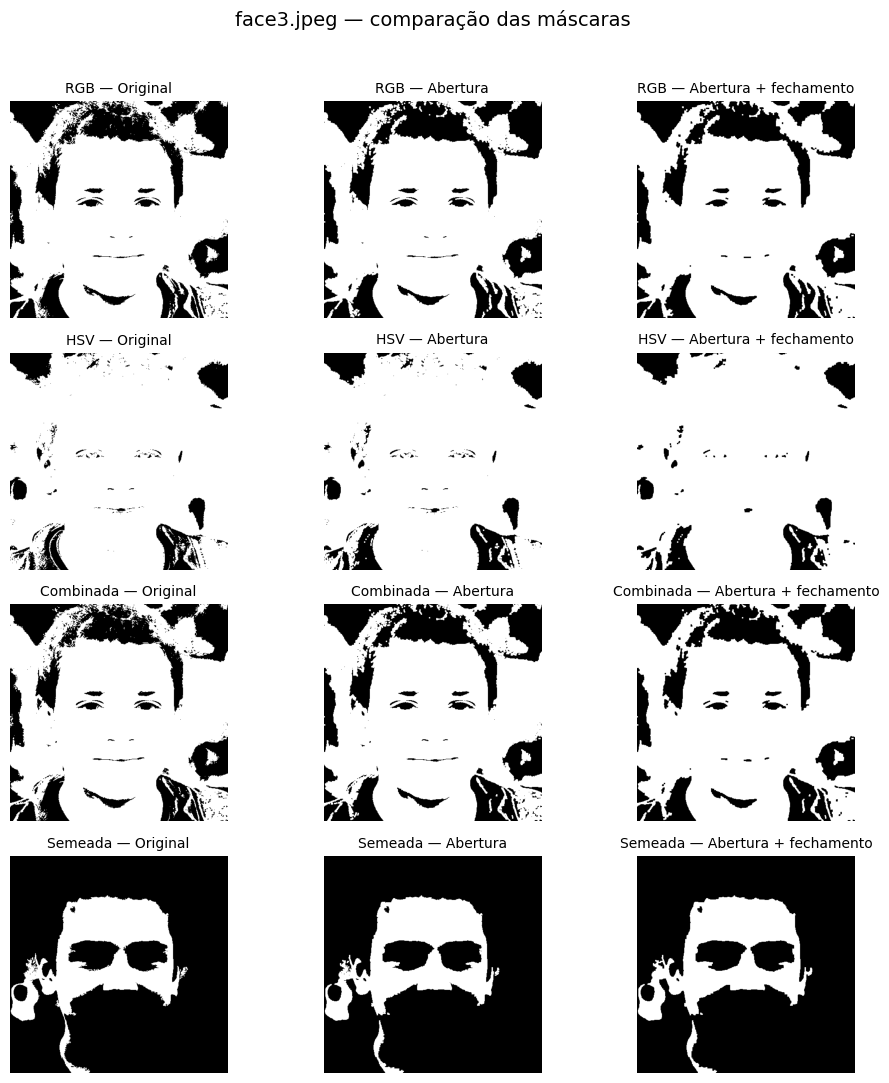

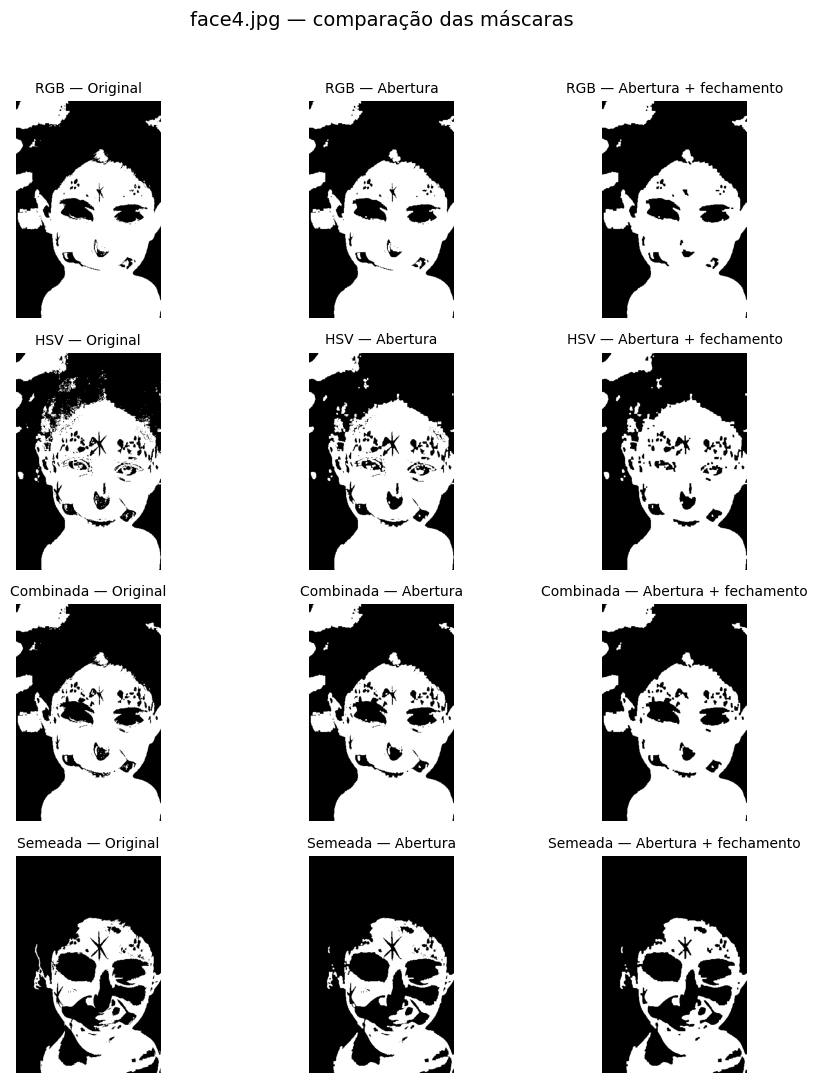

,Imagem,Método,Etapa,Área (%),Componentes (8 vizinhos)
0,face1.jpg,RGB,Antes,37.72,105
1,face1.jpg,RGB,Depois,37.50,20
2,face1.jpg,HSV,Antes,49.66,269
3,face1.jpg,HSV,Depois,48.76,36
4,face1.jpg,Combinada,Antes,37.64,107
5,face1.jpg,Combinada,Depois,37.41,20
6,face1.jpg,Semeada,Antes,16.06,1
7,face1.jpg,Semeada,Depois,15.90,1
8,face2.jpg,RGB,Antes,34.10,76
9,face2.jpg,RGB,Depois,33.81,2


In [14]:
TAMANHO_ABERTURA = 3
TAMANHO_FECHAMENTO = 3
antes_morfologia = {}
depois_morfologia = {}
linhas_morfologia = []

for nome, img in faces.items():
    metodos = {m: mascaras_pele[nome][m] for m in ['RGB', 'HSV', 'Combinada']}
    metodos['Semeada'] = mascaras_semeadas[nome]
    antes_morfologia[nome] = metodos
    depois_morfologia[nome] = {}
    fig, axes = plt.subplots(4, 3, figsize=(10, 11))
    fig.suptitle(f'{nome} — comparação das máscaras', fontsize=14)

    for linha, (metodo, mascara) in enumerate(metodos.items()):
        aberta = abertura(mascara, TAMANHO_ABERTURA)
        final = fechamento(aberta, TAMANHO_FECHAMENTO)
        depois_morfologia[nome][metodo] = final
        for ax, etapa, titulo in zip(axes[linha], [mascara, aberta, final],
                                      ['Original', 'Abertura', 'Abertura + fechamento']):
            ax.imshow(etapa, cmap='gray', vmin=0, vmax=1)
            ax.set_title(f'{metodo} — {titulo}', fontsize=10)
            ax.axis('off')
        for etapa, m in [('Antes', mascara), ('Depois', final)]:
            n, _ = cv2.connectedComponents(m.astype(np.uint8), connectivity=8)
            linhas_morfologia.append({'Imagem': nome, 'Método': metodo,
                'Etapa': etapa, 'Área (%)': 100 * m.mean(),
                'Componentes (8 vizinhos)': n - 1})

    plt.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()

display(pd.DataFrame(linhas_morfologia).round(2))


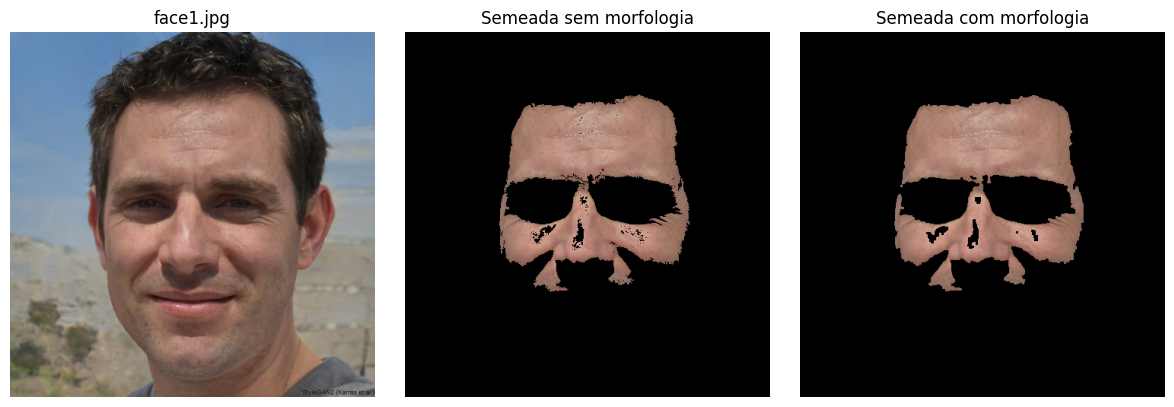

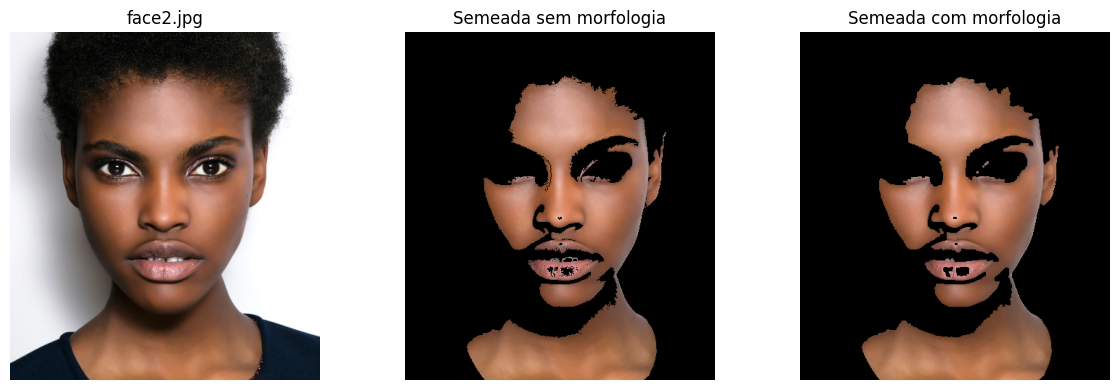

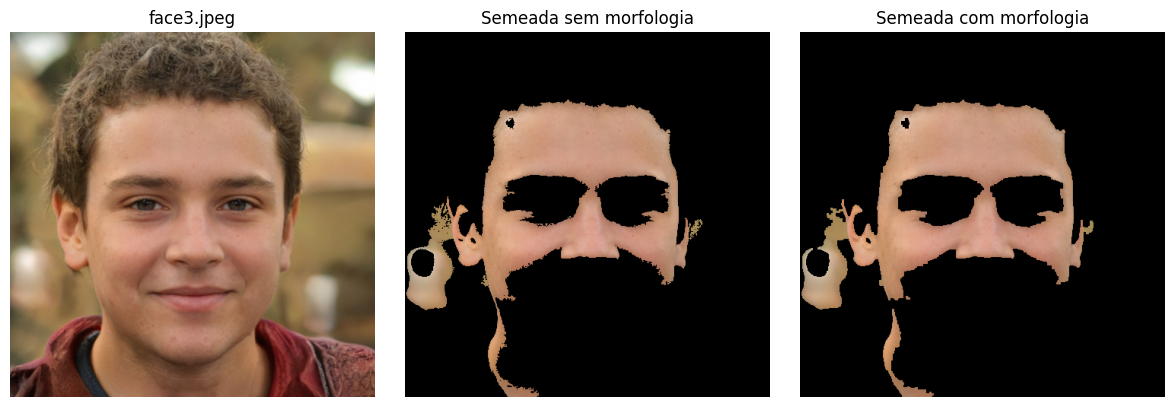

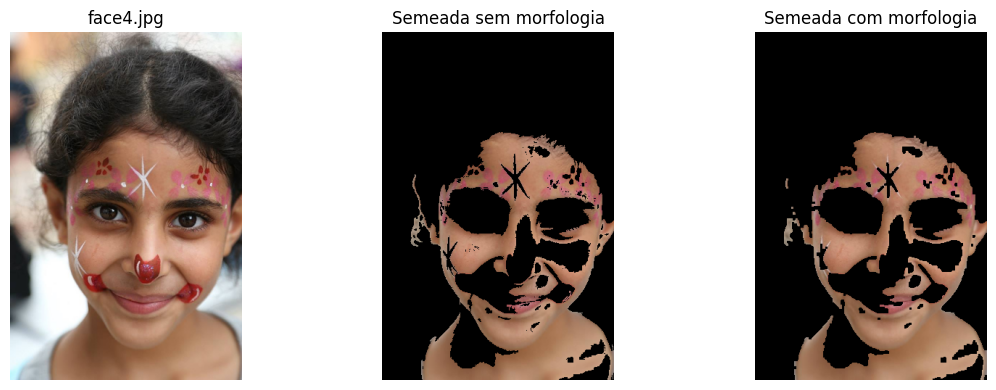

In [15]:
# Comparação da imagem recortada pelo crescimento com e sem morfologia.
for nome, img in faces.items():
    show_images([img, aplicar_mascara(img, mascaras_semeadas[nome]),
                 aplicar_mascara(img, depois_morfologia[nome]['Semeada'])],
                [nome, 'Semeada sem morfologia', 'Semeada com morfologia'])


### 3.2. A morfologia contribui igualmente para os dois métodos?

Não necessariamente. A limiarização decide por pixel e pode produzir muitas
ilhas isoladas; a abertura consegue remover parte delas. O crescimento já exige
uma ligação com a semente, então tende a produzir uma região conectada pela
vizinhança 4, embora possa conter falhas internas e extensões estreitas.
O fechamento pode ajudar a reduzir pequenas falhas nos dois casos.

A contagem da tabela usa vizinhança 8 e serve como diagnóstico: reduzir o
número de componentes pode indicar remoção de ilhas, mas também pode indicar
junção de regiões diferentes. Da mesma forma, aumentar a área não significa
melhorar a máscara. Confira os contornos e o fundo nas imagens.

A abertura pode apagar partes finas da pele ou separar uma região ligada por
uma ponte estreita; o fechamento pode unir rosto, pescoço ou fundo próximo.
Se o crescimento já incorporou uma grande região de fundo, operações 3×3 não
conseguem corrigir esse erro de cor. Morfologia refina a forma da máscara,
mas não sabe distinguir rosto de outras regiões de pele.

Por exemplo, em `face1.jpg` a máscara RGB passa de 105 para 20 componentes,
enquanto a semeada permanece com um componente e muda pouco de área. Isso
é compatível com a remoção de pequenas ilhas na limiarização. Em `face3.jpeg`
e `face4.jpg`, o refinamento chega a separar partes da região semeada ao
remover ligações estreitas. Portanto, os benefícios não são iguais nos dois
métodos, e os erros maiores de seleção do fundo continuam visíveis.


## 4. Métricas de avaliação da segmentação

IoU e Dice podem avaliar máscaras produzidas por qualquer método, inclusive
limiarização, K-means e crescimento de regiões. Não dependem de Deep Learning.
É preciso ter uma máscara de referência, anotada manualmente ou fornecida
pelo dataset, para medir a qualidade da segmentação:

| Métrica | Fórmula | Interpretação |
|---|---|---|
| Precisão | TP / (TP + FP) | Quanto do que foi marcado é realmente pele |
| Recall | TP / (TP + FN) | Quanto da pele verdadeira foi encontrado |
| IoU | TP / (TP + FP + FN) | Sobreposição entre predição e referência |
| Dice / F1 | 2TP / (2TP + FP + FN) | Equilíbrio entre precisão e recall |
| Acurácia | (TP + TN) / total | Proporção de pixels classificados corretamente |

TP: pele corretamente marcada; FP: fundo marcado como pele; FN: pele perdida;
TN: fundo corretamente rejeitado. A acurácia pode parecer alta apenas porque
há muito fundo; por isso IoU, Dice, precisão e recall são complementares.

As imagens em `imgs/` não têm máscaras de referência. Portanto, **não há valores
reais dessas métricas neste experimento**. Área e número de componentes da
seção anterior descrevem as máscaras, mas não medem sua acurácia. Não usamos
a saída de um dos algoritmos como se fosse a resposta correta.


In [16]:
def metricas_segmentacao(predicao, referencia):
    pred = np.asarray(predicao, dtype=bool)
    ref = np.asarray(referencia, dtype=bool)
    if pred.shape != ref.shape:
        raise ValueError('Predição e referência devem ter o mesmo tamanho.')
    tp = np.count_nonzero(pred & ref)
    fp = np.count_nonzero(pred & ~ref)
    fn = np.count_nonzero(~pred & ref)
    tn = np.count_nonzero(~pred & ~ref)

    def dividir(a, b):
        return a / b if b else np.nan  # Métrica indefinida se denominador = 0.

    return {'Precisão': dividir(tp, tp + fp), 'Recall': dividir(tp, tp + fn),
            'IoU': dividir(tp, tp + fp + fn), 'Dice': dividir(2 * tp, 2 * tp + fp + fn),
            'Acurácia': dividir(tp + tn, tp + fp + fn + tn)}

# Quando houver uma máscara anotada, branca para pele e preta para fundo:
# ref = cv2.imread('imgs/gt/face1.png', cv2.IMREAD_GRAYSCALE)
# ref = cv2.resize(ref, (faces['face1.jpg'].shape[1], faces['face1.jpg'].shape[0]),
#                  interpolation=cv2.INTER_NEAREST) > 0
# display(pd.DataFrame([metricas_segmentacao(mascaras_semeadas['face1.jpg'], ref)]))
print('Métricas supervisionadas disponíveis para quando houver máscaras anotadas.')


Métricas supervisionadas disponíveis para quando houver máscaras anotadas.


## 5. Discussão e estudo do código

Os resultados permitem comparar três critérios: cor no K-means RGB,
cor e posição no RGB+XY e cor com conectividade no crescimento de regiões.
Nenhum deles reconhece o significado dos objetos. A escolha de K, os limites
de pele, a semente e a tolerância influenciam diretamente os resultados.

Para estudar, altere um parâmetro por vez e execute novamente a seção:

1. Compare K=3 e K=5 em `2or4objects.jpg` e observe os corações e o fundo.
2. Mude `peso_xy` na função KMeans e observe quando a posição começa a dividir as maçãs.
3. Confira os pontos vermelhos das sementes e compare as tolerâncias de 8%, 15% e 25%.
4. Teste elemento 5×5 na morfologia e observe os detalhes removidos e as regiões unidas.

O notebook contém a implementação e a discussão inicial. O relatório PDF e os
slides exigidos no enunciado são entregas separadas.

## 6. Referências e adaptações

- `docs/Trabalho M2.pdf`: requisitos dos Projetos 1 e 2 e da Opção 2 de Morfologia.
- `docs/ref_organizacao.ipynb`: organização em setup, funções, execução e análise.
- Kolkur, S. et al. (2017). *Human Skin Detection Using RGB, HSV and YCbCr Color
  Models*, pp. 324–332; especialmente a seção 4, p. 328. Cópia em `docs/` e
  [artigo](https://arxiv.org/abs/1708.02694).
- `docs/SkinSegmentation.py`: esqueleto das regras de pele.
- `docs/refs/Pratica1 - Operações Pontuais.ipynb`: apesar da extensão/nome,
  contém o script KMeans3D usado como referência conceitual.
- `docs/refs/Segmentação_por_Crescimento_de_Regiões_Parte_2_Algoritmos_Avançados.ipynb`:
  contém o esqueleto SeedPointSegmentation, adaptado para fila deque e máscara booleana.
- `docs/refs/Segmentação_por_Crescimento_de_Regiões_Parte_1_atualizado.ipynb`:
  contém os exercícios de erosão, dilatação, abertura e fechamento.

Alguns arquivos de `docs/refs` têm nomes/extensões trocados. Foram consultados
pelo conteúdo, sem importá-los diretamente. Substituímos APIs antigas como
`np.int`, evitamos janelas `cv2.imshow` e usamos operações NumPy sobre as
imagens para manter o código curto e executável no notebook.
